In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")


In [3]:

df = pd.read_csv("Mall_Customers.csv")

df.head(10)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [4]:

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data Types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [5]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())


Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Records: 0


In [6]:

income = df["Annual Income (k$)"]

print("Average Annual Income:", income.mean())
print("Median Annual Income:", income.median())
print("Minimum Annual Income:", income.min())
print("Maximum Annual Income:", income.max())


Average Annual Income: 60.56
Median Annual Income: 61.5
Minimum Annual Income: 15
Maximum Annual Income: 137


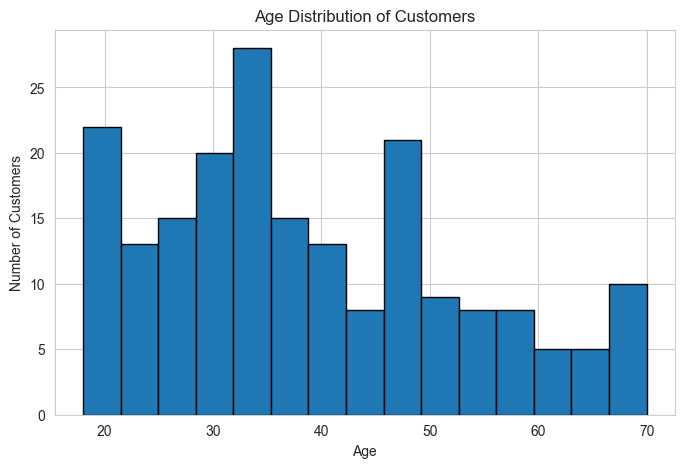

In [7]:

plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=15, edgecolor="black")
plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()


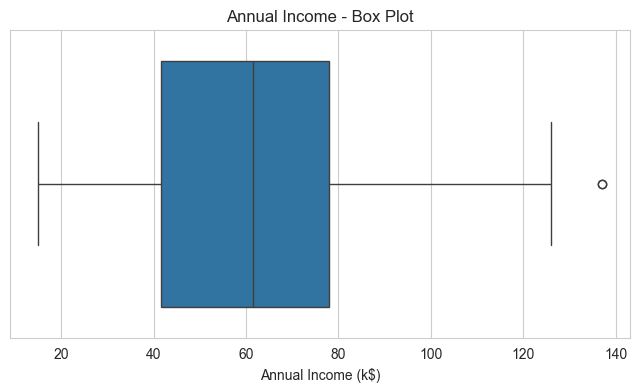

In [8]:

plt.figure(figsize=(8, 4))

sns.boxplot(x=df["Annual Income (k$)"])
plt.title("Annual Income - Box Plot")
plt.xlabel("Annual Income (k$)")

plt.show()


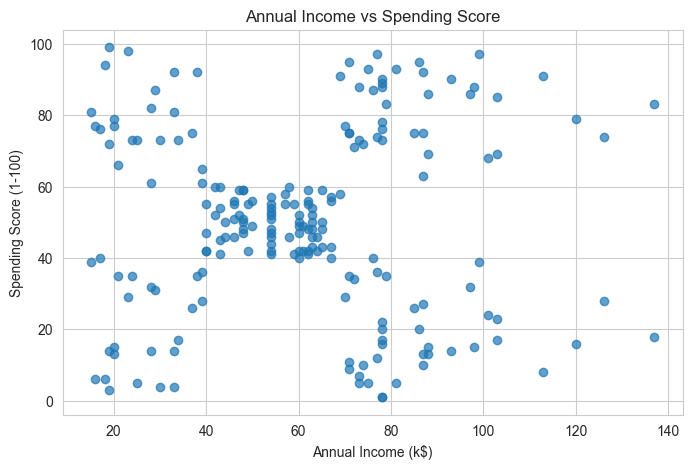

In [9]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.7
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.show()


In [10]:

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

X.head()


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [11]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]


array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992]])

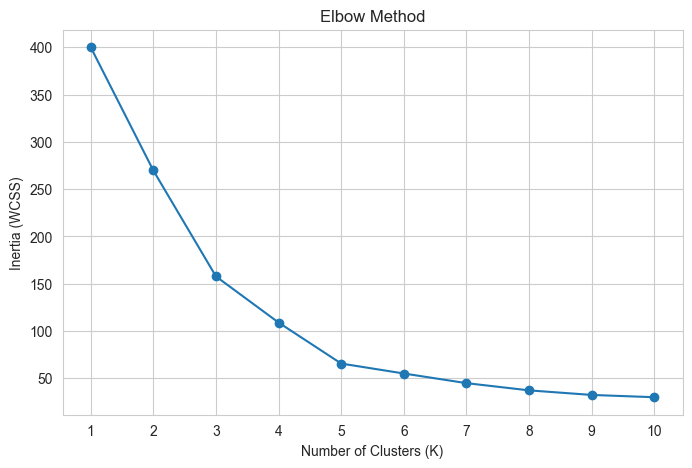

In [12]:

inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(range(1, 11))

plt.show()


In [13]:

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

df.head(10)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


In [14]:

print("Customers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())


Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [15]:

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centroids_df = pd.DataFrame(
    centroids,
    columns=["Annual Income (k$)", "Spending Score (1-100)"]
)

centroids_df.index.name = "Cluster"

centroids_df


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


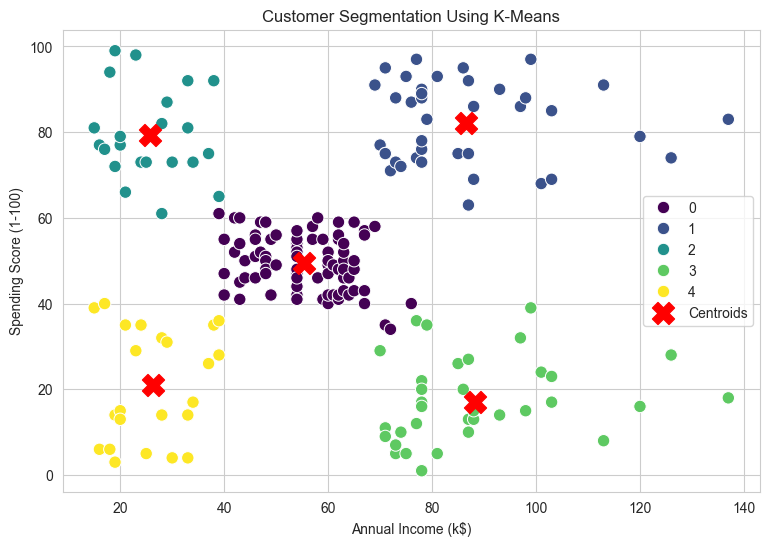

In [16]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()

plt.show()


In [17]:

score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", score)


Silhouette Score: 0.5546571631111091


In [18]:

comparison = []

for k in [4, 5]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    comparison.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df


,K,Inertia,Silhouette Score
0,4,108.921317,0.493907
1,5,65.568408,0.554657


In [19]:

cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_summary


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [20]:

high_income_threshold = df["Annual Income (k$)"].median()
high_spending_threshold = df["Spending Score (1-100)"].median()

high_value_segments = cluster_summary[
    (cluster_summary["Average_Income"] > high_income_threshold) &
    (cluster_summary["Average_Spending_Score"] > high_spending_threshold)
]

print("High-Income and High-Spending Segments:")
high_value_segments


High-Income and High-Spending Segments:


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
1,39,32.69,86.54,82.13
